In [1]:
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os

In [79]:
img_array = cv2.imread("Test_Dataset/Closed_Eyes/s0001_00056_0_0_0_0_0_01.png", cv2.IMREAD_GRAYSCALE) #read pics from add

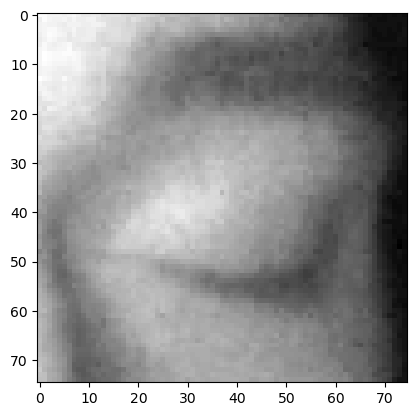

In [81]:
plt.imshow(img_array,cmap="gray") #show pics in gray

In [83]:
img_array.shape

(75, 75)

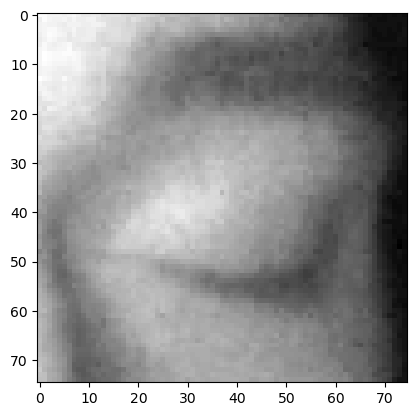

In [89]:
import cv2
import os
import matplotlib.pyplot as plt

Datadirectory = "Test_Dataset/"  # training dataset want to train
Classes = ["Closed_Eyes", "Open_Eyes"]  # 2 lists

# Specific image
specific_image = "s0001_00056_0_0_0_0_0_01.png"

# วนลูปผ่านแต่ละคลาสในลิสต์ Classes
for category in Classes:
    path = os.path.join(Datadirectory, category)
     
    for img in os.listdir(path):
        if img == specific_image: # ตรวจสอบว่าไฟล์ภาพตรงกับชื่อที่เราต้องการหรือไม่
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            backtorgb = cv2.cvtColor(img_array, cv2.COLOR_GRAY2RGB)
            plt.imshow(img_array, cmap="gray")
            plt.show()
            break
    break

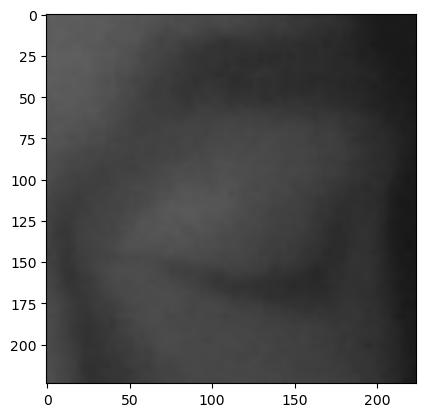

In [91]:
img_size = 224 

new_array = cv2.resize(backtorgb, (img_size, img_size))
plt.imshow(new_array , cmap="gray") 
plt.show()

reading all the images converting them into an array for data and labels

In [94]:
training_Data = [] # สร้างลิสต์สำหรับเก็บข้อมูลการฝึก

def create_training_Data():
    for category in Classes:
        path = os.path.join(Datadirectory , category)
        class_num = Classes.index(category) #(0 สำหรับ Closed_Eyes, 1 สำหรับ Open_Eyes)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path,img), cv2.IMREAD_GRAYSCALE)
                backtorgb = cv2.cvtColor(img_array, cv2.COLOR_GRAY2RGB)
                new_array = cv2.resize(backtorgb,(img_size, img_size))
                training_Data.append([new_array, class_num]) # เพิ่มภาพที่ถูกรีไซส์และหมายเลขคลาสลงในลิสต์ training_Data
            except Exception as e:
                pass

In [96]:
create_training_Data() # เรียกใช้ฟังก์ชันเพื่อสร้างข้อมูลการฝึก

In [98]:
print(len(training_Data)) 

3232


In [100]:
import random
random.shuffle(training_Data) # สุ่มลำดับข้อมูลการฝึก

In [102]:
X = []
y = []

for features,label in training_Data : 
    X.append(features) # เก็บข้อมูลfeaturesในลิสต์ X
    y.append(label) # เก็บlabelนลิสต์ y

X = np.array(X).reshape(-1, img_size, img_size, 3) 

In [104]:
X.shape

(3232, 224, 224, 3)

In [106]:
X= X/255.0; # ปรับขนาดค่าพิกเซลของภาพให้อยู่ในช่วง 0 ถึง 1

In [108]:
Y=np.array(y)

In [110]:
import pickle

pickle_out = open("X.pickle", "wb") #write binary
pickle.dump(X, pickle_out)
pickle_out.close()

pickle_out = open("y.pickle", "wb")
pickle.dump(y,  pickle_out)
pickle_out.close()

In [112]:
pickle_in = open("X.pickle", "rb")
X = pickle.load(pickle_in) #read binary

pickle_in = open("y.pickle", "rb")
y = pickle.load(pickle_in)

deep learning model for training - Training Learning

In [164]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [267]:
base_model = tf.keras.applications.MobileNet(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

In [269]:
base_input = base_model.input
base_output = base_model.output

In [271]:
flat_layer = layers.Flatten()(base_output)
final_output = layers.Dense(1, activation='sigmoid')(flat_layer) #เวกเตอร์ 1 มิติ sigmoid เพื่อให้ผลลัพธ์เป็นค่าระหว่าง 0 และ 1

In [273]:
new_model = keras.Model(inputs=base_input, outputs=final_output) # สร้างโมเดลใหม่ที่รวมโมเดล MobileNet

In [275]:
new_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']) # ใช้ความแม่นยำ 

In [277]:
new_model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv2D)                       │ (None, 112, 112, 32)        │             864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1_bn (BatchNormalization)        │ (None, 112, 112, 32)        │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1_relu (ReLU)                    │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_1 (DepthwiseConv2D)          │ (None, 112, 112, 32)        │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_1_bn (BatchNormalization)    │ (None, 112, 112, 32)        │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_1_relu (ReLU)                │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_1 (Conv2D)                   │ (None, 112, 112, 64)        │           2,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_1_bn (BatchNormalization)    │ (None, 112, 112, 64)        │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_1_relu (ReLU)                │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pad_2 (ZeroPadding2D)           │ (None, 113, 113, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_2 (DepthwiseConv2D)          │ (None, 56, 56, 64)          │             576 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_2_bn (BatchNormalization)    │ (None, 56, 56, 64)          │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_2_relu (ReLU)                │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_2 (Conv2D)                   │ (None, 56, 56, 128)         │           8,192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_2_bn (BatchNormalization)    │ (None, 56, 56, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_2_relu (ReLU)                │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_3 (DepthwiseConv2D)          │ (None, 56, 56, 128)         │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_3_bn (BatchNormalization)    │ (None, 56, 56, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_3_relu (ReLU)                │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_3 (Conv2D)                   │ (None, 56, 56, 128)         │          16,384 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 3,279,041 (12.51 MB)

 Trainable params: 3,257,153 (12.43 MB)

 Non-trainable params: 21,888 (85.50 KB)

In [279]:
# Assuming X and Y are your training data and labels
new_model.fit(X, Y, epochs=10, validation_split=0.1)

Epoch 1/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.9030 - loss: 0.8977 - val_accuracy: 0.8333 - val_loss: 2.1106
Epoch 2/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.9736 - loss: 0.1311 - val_accuracy: 0.8086 - val_loss: 0.9066
Epoch 3/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.9665 - loss: 0.2272 - val_accuracy: 0.9753 - val_loss: 0.4148
Epoch 4/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.9872 - loss: 0.0322 - val_accuracy: 0.9753 - val_loss: 0.1444
Epoch 5/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.9913 - loss: 0.0207 - val_accuracy: 0.9691 - val_loss: 0.2045
Epoch 6/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.9911 - loss: 0.0236 - val_accuracy: 0.9753 - val_loss: 0.0861
Epoch 7/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.9942 - loss: 0.0136 - val_accuracy: 0.9660 - val_loss: 0.1851
Epoch 8/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.9722 - v

In [281]:
new_model.save('my_model_Dowsiness.h5')

In [283]:
loaded_model = tf.keras.models.load_model('my_model_Dowsiness.h5') #โหลดโมเดลที่บันทึกไว้ก่อนหน้านี้เพื่อใช้ในการทำนายใหม่หรือทำการฝึกต่อ

In [325]:
img_array = cv2.imread('C:/Users/Paint/Desktop/s0001_00155_0_0_0_0_0_01.png', cv2.IMREAD_GRAYSCALE)
backtorgb = cv2.cvtColor(img_array, cv2.COLOR_GRAY2RGB)
new_array = cv2.resize(backtorgb,( img_size,img_size))

In [327]:
X_input = np.array(new_array).reshape(1, img_size, img_size, 3)

In [329]:
X_input = X_input / 255.0  

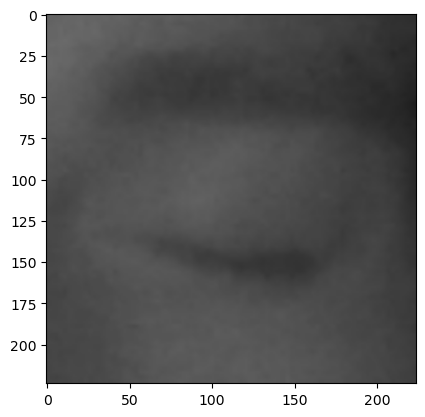

In [331]:
plt.imshow(new_array)
plt.show()

In [333]:
new_model = tf.keras.models.load_model('my_model_Dowsiness.h5') #โหลดโมเดลที่เซฟมา

In [335]:
prediction = new_model.predict(X_input) # ใช้โมเดลในการทำนายผลลัพธ์จากภาพ

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step


In [337]:
print("Prediction:", prediction)

Prediction: [[3.2085062e-12]]


In [339]:
if prediction >= 0.5:
    print("Prediction: Eyes Open")
else:
    print("Prediction: Eyes Closed") 

Prediction: Eyes Closed


In [341]:
img = cv2.imread('C:/Users/Paint/Desktop/sad_woman.png')

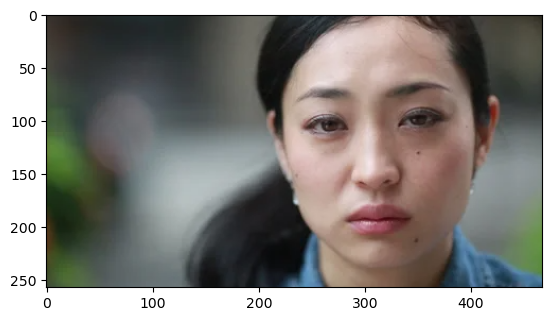

In [343]:
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

In [345]:
faceCascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

In [347]:
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')

In [349]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # แปลงภาพเป็นขาวดำเพื่อใช้ในการตรวจจับ

In [351]:
eyes = eye_cascade.detectMultiScale(gray,1.1,4)

In [353]:
for(x,y,w,h) in eyes:
    cv2.rectangle(img,(x,y), (x+w , y+h), (0,255,0),2) # วาดกรอบสี่เหลี่ยมรอบดวงตาที่ตรวจจับได้

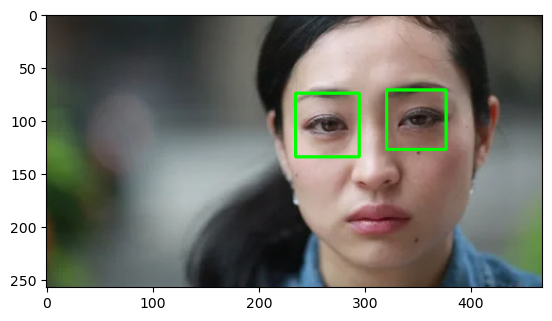

In [355]:
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

In [357]:
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')

# แปลงภาพเป็น grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ตรวจจับตาในภาพ
eyes = eye_cascade.detectMultiScale(gray, 1.1, 4)

# วนลูปผ่านตาที่ตรวจจับได้
for x, y, w, h in eyes:
    # ดึงพื้นที่ของตาจากภาพ grayscale
    roi_gray = gray[y:y+h, x:x+w]
    # ดึงพื้นที่ของตาจากภาพสี
    roi_color = img[y:y+h, x:x+w]
    
    # ตรวจจับตาอีกครั้งในพื้นที่ที่ดึงมาจากภาพ grayscale
    eyess = eye_cascade.detectMultiScale(roi_gray)
    
    if len(eyess) == 0:
        print("eyes are not detected")
    else:
        for (ex, ey, ew, eh) in eyess:
            # ดึงตาที่ตรวจจับได้จากพื้นที่ที่ดึงมา
            eyes_roi = roi_color[ey:ey+eh, ex:ex+ew]

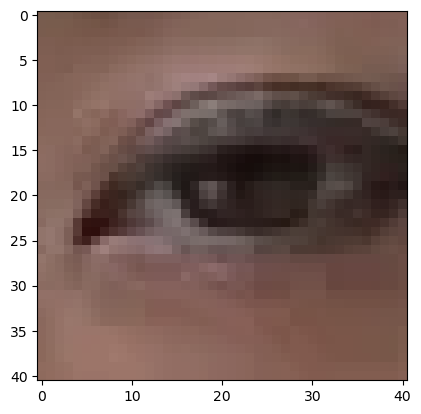

In [359]:
plt.imshow(cv2.cvtColor(eyes_roi, cv2.COLOR_BGR2RGB))

In [361]:
eyes_roi.shape

(41, 41, 3)

In [363]:
final_image =cv2.resize(eyes_roi , (224,224)) #โมเดลถูกฝึกมาพร้อมกับขนาด 224x224 
final_image = np.expand_dims(final_image, axis=0)
final_image = final_image/255.0

In [365]:
final_image.shape

(1, 224, 224, 3)

In [367]:
new_model.predict(final_image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


array([[1.]], dtype=float32)

In [ ]:
import cv2
import numpy as np
import tensorflow as tf

# โหลดโมเดลที่ฝึกแล้ว
new_model = tf.keras.models.load_model('my_model_Dowsiness.h5')

# โหลด Haar cascade สำหรับการตรวจจับใบหน้าและตา
faceCascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')

# เปิดกล้อง
cap = cv2.VideoCapture(1)  # ใช้กล้องที่ 1
if not cap.isOpened():
    cap = cv2.VideoCapture(0)  # ใช้กล้องที่ 0 ถ้ากล้องที่ 1 ไม่ได้ผล
if not cap.isOpened():
    raise IOError("Cannot open Webcam")

# กำหนดฟอนต์สำหรับการแสดงผลข้อความ
font = cv2.FONT_HERSHEY_SIMPLEX

while True:
    ret, frame = cap.read()
    if not ret:
        break
    
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = faceCascade.detectMultiScale(gray, 1.1, 4)

    for (x, y, w, h) in faces:
        roi_gray = gray[y:y+h, x:x+w]
        roi_color = frame[y:y+h, x:x+w]
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)
        
        eyes = eye_cascade.detectMultiScale(roi_gray)
        if len(eyes) == 0:
            print("Eyes are not detected")
        else:
            for (ex, ey, ew, eh) in eyes:
                eyes_roi = roi_color[ey:ey+eh, ex:ex+ew]
                
                # ตรวจสอบขนาดของรูปร่าง
                if eyes_roi.shape[0] > 0 and eyes_roi.shape[1] > 0:
                    final_image = cv2.resize(eyes_roi, (224, 224))
                    final_image = np.expand_dims(final_image, axis=0)
                    final_image = final_image / 255.0
                    
                    # การทำนาย
                    prediction = new_model.predict(final_image)
                    if prediction > 0.5:  # ใช้ค่าที่เหมาะสมในการตัดสินใจ
                        status = "Open Eyes"
                    else:
                        status = "Closed Eyes"
                    
                    cv2.putText(frame, status, (50, 50), font, 1, (0, 0, 255), 2, cv2.LINE_AA)

    # แสดงผลลัพธ์
    cv2.imshow('Drowsiness Detection Tutorial', frame)

    # ออกจากลูปเมื่อกด 'q'
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# ปล่อยกล้อง
cap.release()
cv2.destroyAllWindows()


Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are not detected
Eyes are n

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Eyes are not detected
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Eyes are not detected
Eyes are not detected
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Eyes are not detected
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Eyes are not detected
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Eyes are not detected
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Eyes are not detected
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Eyes are 

if eyes are closed for unusual time , like more than blinks , like few seconds , alar generate

In [14]:
import cv2
import numpy as np
import tensorflow as tf
import winsound

# โหลดโมเดลที่ฝึกแล้วตาเปิดหรือปิด
new_model = tf.keras.models.load_model('my_model_Dowsiness.h5')


faceCascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')

# เปิดกล้อง
cap = cv2.VideoCapture(1)  
if not cap.isOpened():
    cap = cv2.VideoCapture(0) 
if not cap.isOpened():
    raise IOError("Cannot open Webcam")

frequency = 2500
duration = 1000  # ระยะเวลาเสียงเตือน (1วินาที)
counter = 0
#อ่านภาพจากกล้อง
while True:
    ret, frame = cap.read()
    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) #แปลงภาพเป็นโทนสีเทาเพื่อการตรวจจับ
    faces = faceCascade.detectMultiScale(gray, 1.1, 4)

    for (x, y, w, h) in faces:  
        roi_gray = gray[y:y+h, x:x+w] 
        roi_color = frame[y:y+h, x:x+w]
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2) # วาดกรอบสี่เหลี่ยมรอบใบหน้า
        
        eyes = eye_cascade.detectMultiScale(roi_gray) #จับตาในพื้นที่ของใบหน้า
        if len(eyes) == 0:
            print("Eyes are not detected")
        else:
            for (ex, ey, ew, eh) in eyes: 
                eyes_roi = roi_color[ey:ey+eh, ex:ex+ew] #ใช้พิกัด ey, ex, eh, ew เพื่อดึงพื้นที่ของตา
                
                if eyes_roi.shape[0] > 0 and eyes_roi.shape[1] > 0: # ตรวจสอบว่าพื้นที่ของตาที่ดึงมามีขนาดที่ถูกต้อง
                    final_image = cv2.resize(eyes_roi, (224, 224))
                    final_image = np.expand_dims(final_image, axis=0)
                    final_image = final_image / 255.0

                    
                    Predictions = new_model.predict(final_image)
                    if Predictions > 0.5:  # ใช้ค่าที่เหมาะสมในการตัดสินใจ
                        status = "Open Eyes"
                        cv2.putText(frame, status, (150, 150), cv2.FONT_HERSHEY_SIMPLEX, 3, (0, 255, 0), 2, cv2.LINE_4) 
                        x1, y1, w1, h1 = 0, 0, 175, 175
                        cv2.rectangle(frame, (x1, y1), (x1+w1, y1+h1), (0, 0, 0), -1)  
                        cv2.putText(frame, 'Active', (x1 + int(w1/10), y1 + int(h1/2)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
                    else:
                        counter += 1 
                        status = "Closed Eyes"
                        cv2.putText(frame, status, (150, 150), cv2.FONT_HERSHEY_SIMPLEX, 3, (0, 0, 255), 2, cv2.LINE_4)
                        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 0, 255), 2) 
                        if counter > 5:   
                            x1, y1, w1, h1 = 0, 0, 175, 175
                            cv2.rectangle(frame, (x1, y1), (x1+w1, y1+h1), (0, 0, 0), -1)
                            cv2.putText(frame, 'Sleep Alert !!', (x1 + int(w1/10), y1 + int(h1/2)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
                            winsound.Beep(frequency, duration) # ส่งเสียงเตือน
                            counter = 0  #รีเซ็ตค่าตัวนับ

    
    cv2.imshow('Drowsiness Detection Tutorial', frame)


    if cv2.waitKey(1) & 0xFF == ord('q'):
        break


cap.release()
cv2.destroyAllWindows()


Eyes are not detected
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s